# Phishing website detection lab
PRT565 Assessment 4. This notebook walks through the complete, reproducible experiment and shows the saved evidence used in the report. Read README.md first.

**Research question:** which machine-learning or deep-learning model most reliably separates phishing websites from legitimate ones, using 30 pre-extracted indicators, when repeated inputs are prevented from leaking between training and testing?

**Models compared:** the four required models (Decision Tree, Random Forest, Categorical Naive Bayes, Multilayer ANN), four additional algorithms (Logistic Regression, k-NN, SVM, Gradient Boosting), a deeper 3-layer ANN, and two recurrent deep-learning models (LSTM, simple RNN) in `deep_learning_extension.py`.

In [1]:
from pathlib import Path
import os
import sys

# Locate the project before importing its training module.
candidates = [Path.cwd(), Path.cwd() / 'project', Path.cwd().parent]
ROOT = next((p.resolve() for p in candidates if (p / 'train.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open the extracted project folder in VS Code, '
                            'or launch this notebook with Start_Mac.command.')
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
try:
    import json
    import pandas as pd
    from IPython.display import display, Image
    from train import load_data, main
except ImportError as exc:
    raise ImportError('Select the PRT565 Phishing (.venv) kernel after running '
                      'Start_Mac.command. Missing dependency: ' + str(exc)) from exc
print('Project:', ROOT)
print('Python:', sys.executable)


Project: /Users/newstart/Downloads/Sydney_Group_1_Assessment4 2/project
Python: /opt/homebrew/Caskroom/miniforge/base/envs/prt565/bin/python


## 1. Dataset description
Each row contains encoded indicators, not a raw URL. The original target -1 becomes phishing = 1 (the positive class).

In [2]:
X, y, groups, source = load_data()
display(X.head())
display(y.value_counts().rename(index={0:"Legitimate",1:"Phishing"}))
print("Rows:", len(X), "Features:", X.shape[1], "Unique patterns:", len(set(groups)))

,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,RightClick,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,1,-1,-1,-1,-1,1,1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,1,-1,-1,0,-1,1,1,1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,1,-1,1,-1,1,0,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,1,-1,-1,1,-1,1,-1,1
4,1,0,-1,1,1,-1,1,1,-1,1,...,1,-1,1,-1,-1,0,-1,1,1,1


Result
Legitimate    6157
Phishing      4898
Name: count, dtype: int64

Rows: 11055 Features: 30 Unique patterns: 5785


Encoded categories are feature-specific indicators: URL_Length=1 is not a length of one character. Consult the original feature documentation for each code.

## 2. Dataset analysis (EDA)
Class balance is moderate (44% phishing), so accuracy alone is informative but precision/recall/F1 are still needed. Mutual information is computed on development rows only.

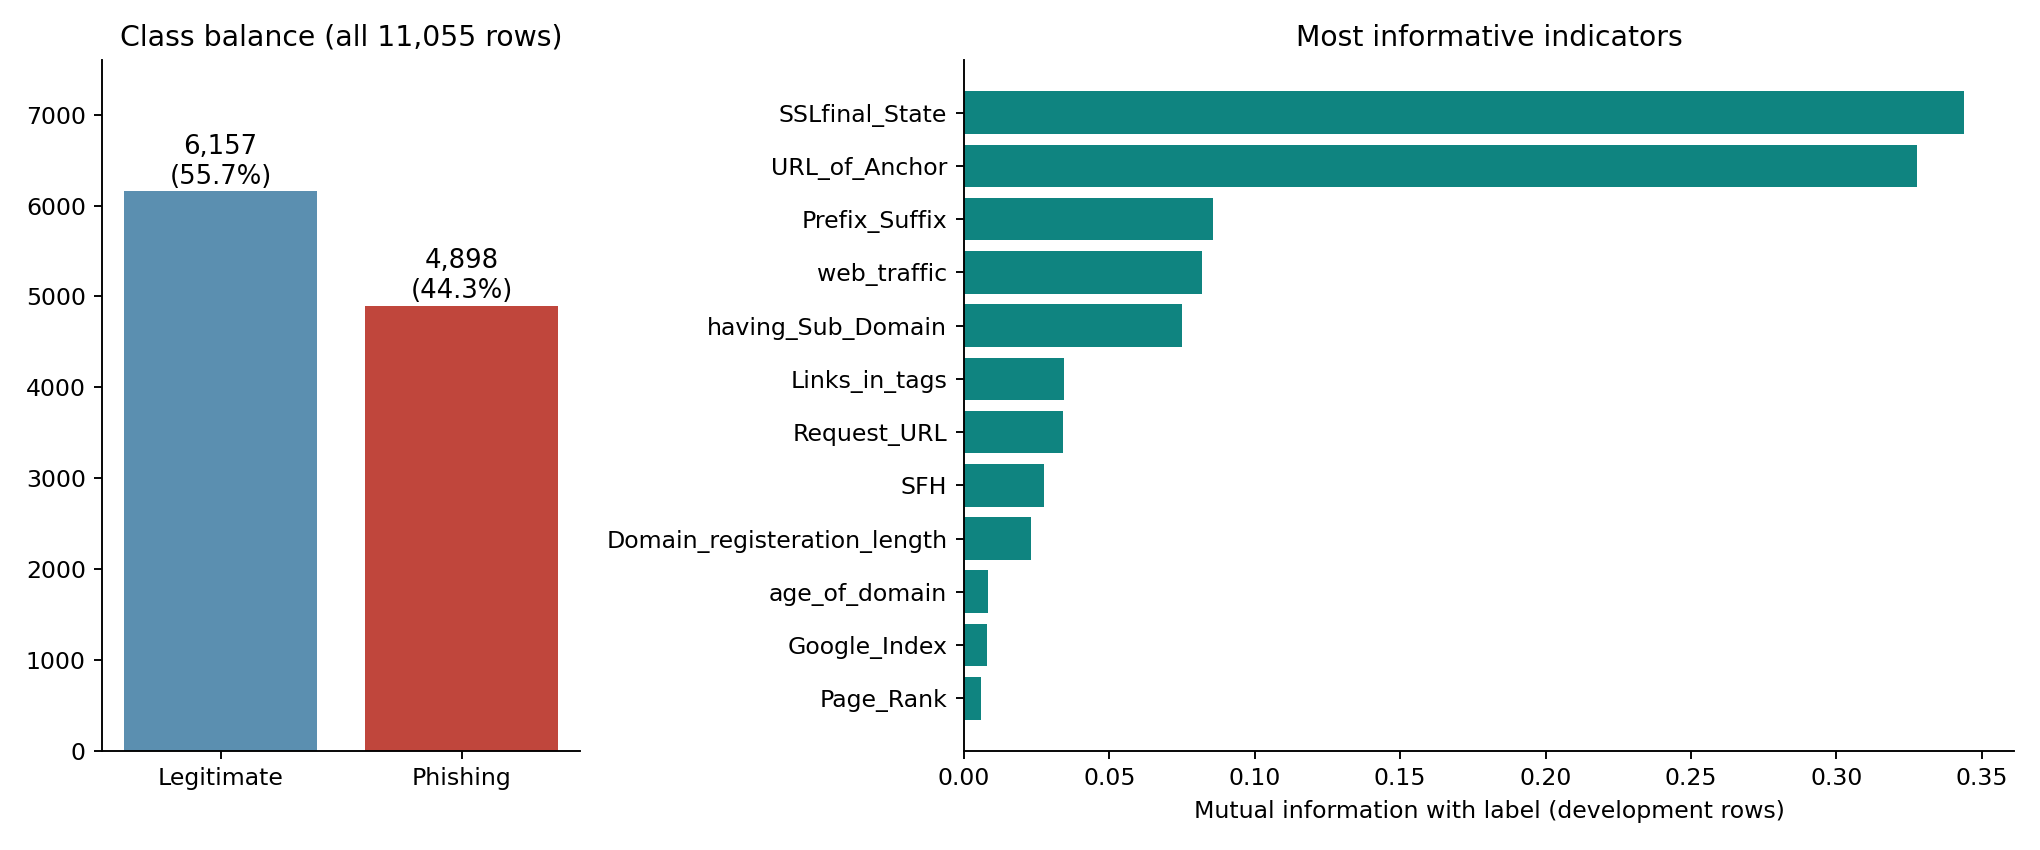

,mutual_information
SSLfinal_State,0.3440
URL_of_Anchor,0.3279
Prefix_Suffix,0.0856
web_traffic,0.0819
having_Sub_Domain,0.0750
Links_in_tags,0.0344
Request_URL,0.0340
SFH,0.0276
Domain_registeration_length,0.0230
age_of_domain,0.0082


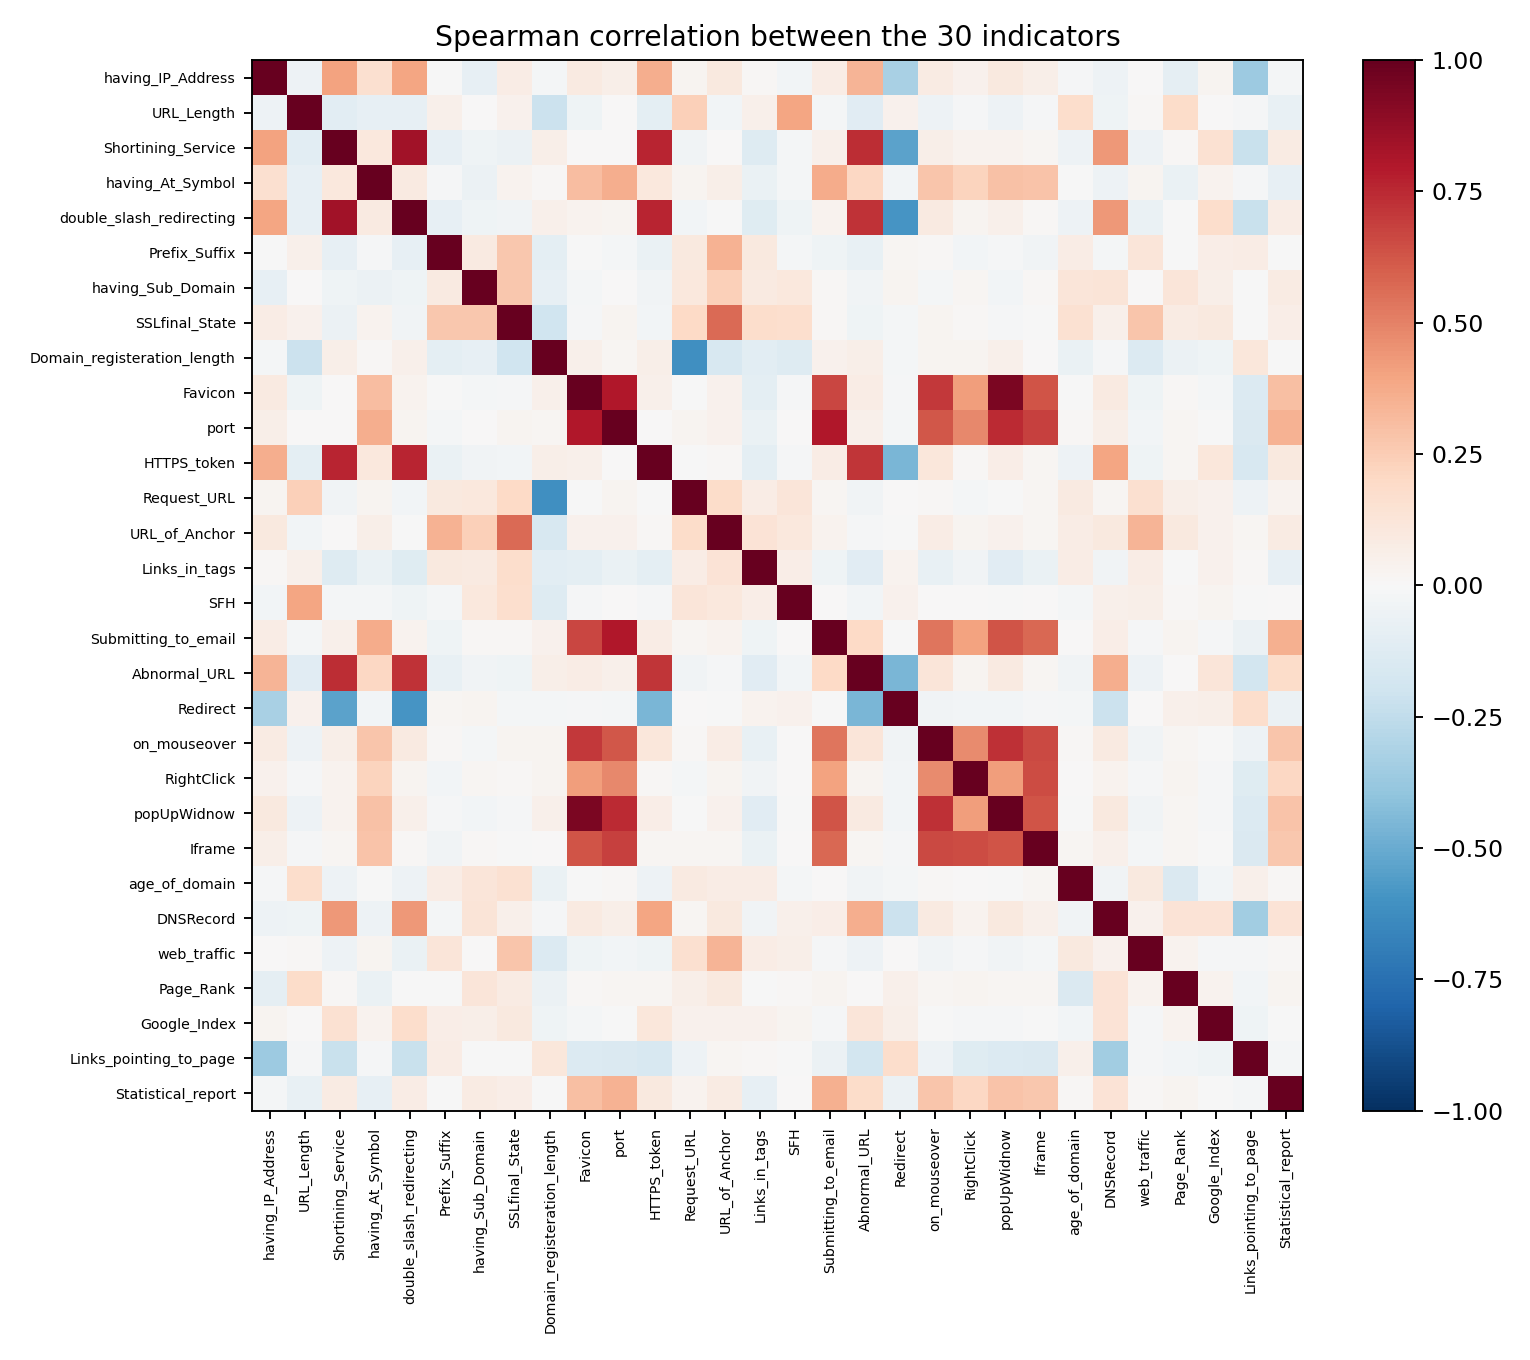

In [3]:
display(Image(filename=str(ROOT/'results/eda_overview.png')))
display(pd.read_csv(ROOT/'results/eda_mutual_information.csv', index_col=0).head(10).round(4))
display(Image(filename=str(ROOT/'results/eda_correlation.png')))

## 3. Reproduce the experiment
The saved run is already complete. Set `RUN_TRAINING=True` to regenerate `results/` with `train.py`; runtime varies by environment. Set `RUN_DEEP_LEARNING=True` to also run the optional LSTM/RNN extension (requires `pip install -r requirements-deep-learning.txt`). Outputs overwrite `results/`; copy that folder first if you need the original evidence.

In [4]:
RUN_TRAINING = False
RUN_DEEP_LEARNING = False
if RUN_TRAINING:
    main()
if RUN_DEEP_LEARNING:
    import deep_learning_extension
    deep_learning_extension.main()
if not (RUN_TRAINING or RUN_DEEP_LEARNING):
    print('Exploring included benchmark outputs; training skipped.')

Exploring included benchmark outputs; training skipped.


## 4. Preprocessing, audit and group-safe split
Identical input patterns form groups kept apart across partitions. Conflicting labels are retained. The nine scikit-learn candidates use the same three grouped folds; train.py selects by development CV F1. Recurrent validation separately selects epochs and is not an untouched estimate.

In [5]:
audit=json.loads((ROOT/"results/audit.json").read_text())
display(audit)
display(pd.read_csv(ROOT/"results/cv_summary.csv"))
manifest=pd.read_csv(ROOT/"results/split_manifest.csv")
assert manifest.groupby("group")["split"].nunique().max()==1
print("No identical feature group crosses the final split.")

{'rows': 11055,
 'features': 30,
 'missing': 0,
 'duplicate_feature_rows': 5270,
 'duplicate_full_rows': 5206,
 'unique_feature_patterns': 5785,
 'conflicting_label_patterns': 64,
 'phishing': 4898,
 'legitimate': 6157,
 'train_rows': 8845,
 'test_rows': 2210,
 'train_phishing': 3919,
 'test_phishing': 979,
 'split_seed': 565,
 'target_mapping': {'original_-1': 'phishing=1', 'original_1': 'legitimate=0'},
 'sha256_arff': '3bcf93b1612306537ee2737751f1bac185b2a77886ab376644c3bf0c7f7cb3e6'}

,model,required,cv_f1,cv_sd,train_cv_f1,search_seconds,parameters
0,Decision Tree,True,0.917146,0.008895,0.960882,0.821010,"{'model__max_depth': None, 'model__min_samples..."
1,Random Forest,True,0.945409,0.005626,0.988117,9.097670,"{'model__max_depth': None, 'model__min_samples..."
2,Categorical NB,True,0.917650,0.005455,0.920601,0.252625,{'model__alpha': 1.0}
3,Multilayer ANN,True,0.936242,0.006566,0.982915,18.342246,{'model__alpha': 0.01}
4,Logistic Regression,False,0.929918,0.006979,0.933234,0.618069,{'model__C': 10.0}
5,k-Nearest Neighbours,False,0.924727,0.006218,0.988079,9.702912,"{'model__n_neighbors': 15, 'model__weights': '..."
6,SVM (RBF),False,0.942340,0.005284,0.976875,40.556456,{'model__C': 10.0}
7,Gradient Boosting,False,0.945714,0.004866,0.980524,5.902299,"{'model__learning_rate': 0.1, 'model__max_leaf..."
8,Deep ANN (3 layers),False,0.942841,0.009606,0.987173,28.068101,{'model__alpha': 0.01}
9,Top 10 Random Forest,False,0.923941,0.009281,NaN,NaN,Fixed best full-model settings; exploratory ex...


No identical feature group crosses the final split.


## 5. Held-out test results
Phishing is the positive class. `f1_ci_low/high` is a 95% group-bootstrap confidence interval (1,000 resamples of whole input-pattern groups).

,model,accuracy,precision,recall,f1,f1_ci_low,f1_ci_high,roc_auc,TN,FP,FN,TP
0,Decision Tree,0.9339,0.9380,0.9111,0.9244,0.9024,0.9442,0.9593,1172,59,87,892
1,Random Forest,0.9611,0.9551,0.9571,0.9561,0.9399,0.9709,0.9933,1187,44,42,937
2,Categorical NB,0.9294,0.9309,0.9081,0.9193,0.8976,0.9401,0.9811,1165,66,90,889
3,Multilayer ANN,0.9439,0.9505,0.9213,0.9357,0.9149,0.9560,0.9915,1184,47,77,902
4,Logistic Regression,0.9335,0.9306,0.9183,0.9244,0.9024,0.9447,0.9861,1164,67,80,899
5,k-Nearest Neighbours,0.9398,0.9443,0.9183,0.9311,0.9119,0.9485,0.9853,1178,53,80,899
6,SVM (RBF),0.9538,0.9611,0.9336,0.9472,0.9283,0.9653,0.9917,1194,37,65,914
7,Gradient Boosting,0.9489,0.9446,0.9397,0.9421,0.9235,0.9605,0.9933,1177,54,59,920
8,Deep ANN (3 layers),0.9507,0.9718,0.9152,0.9427,0.9230,0.9612,0.9928,1205,26,83,896
9,Top 10 Random Forest,0.9416,0.9225,0.9479,0.9350,0.9159,0.9531,0.9846,1153,78,51,928


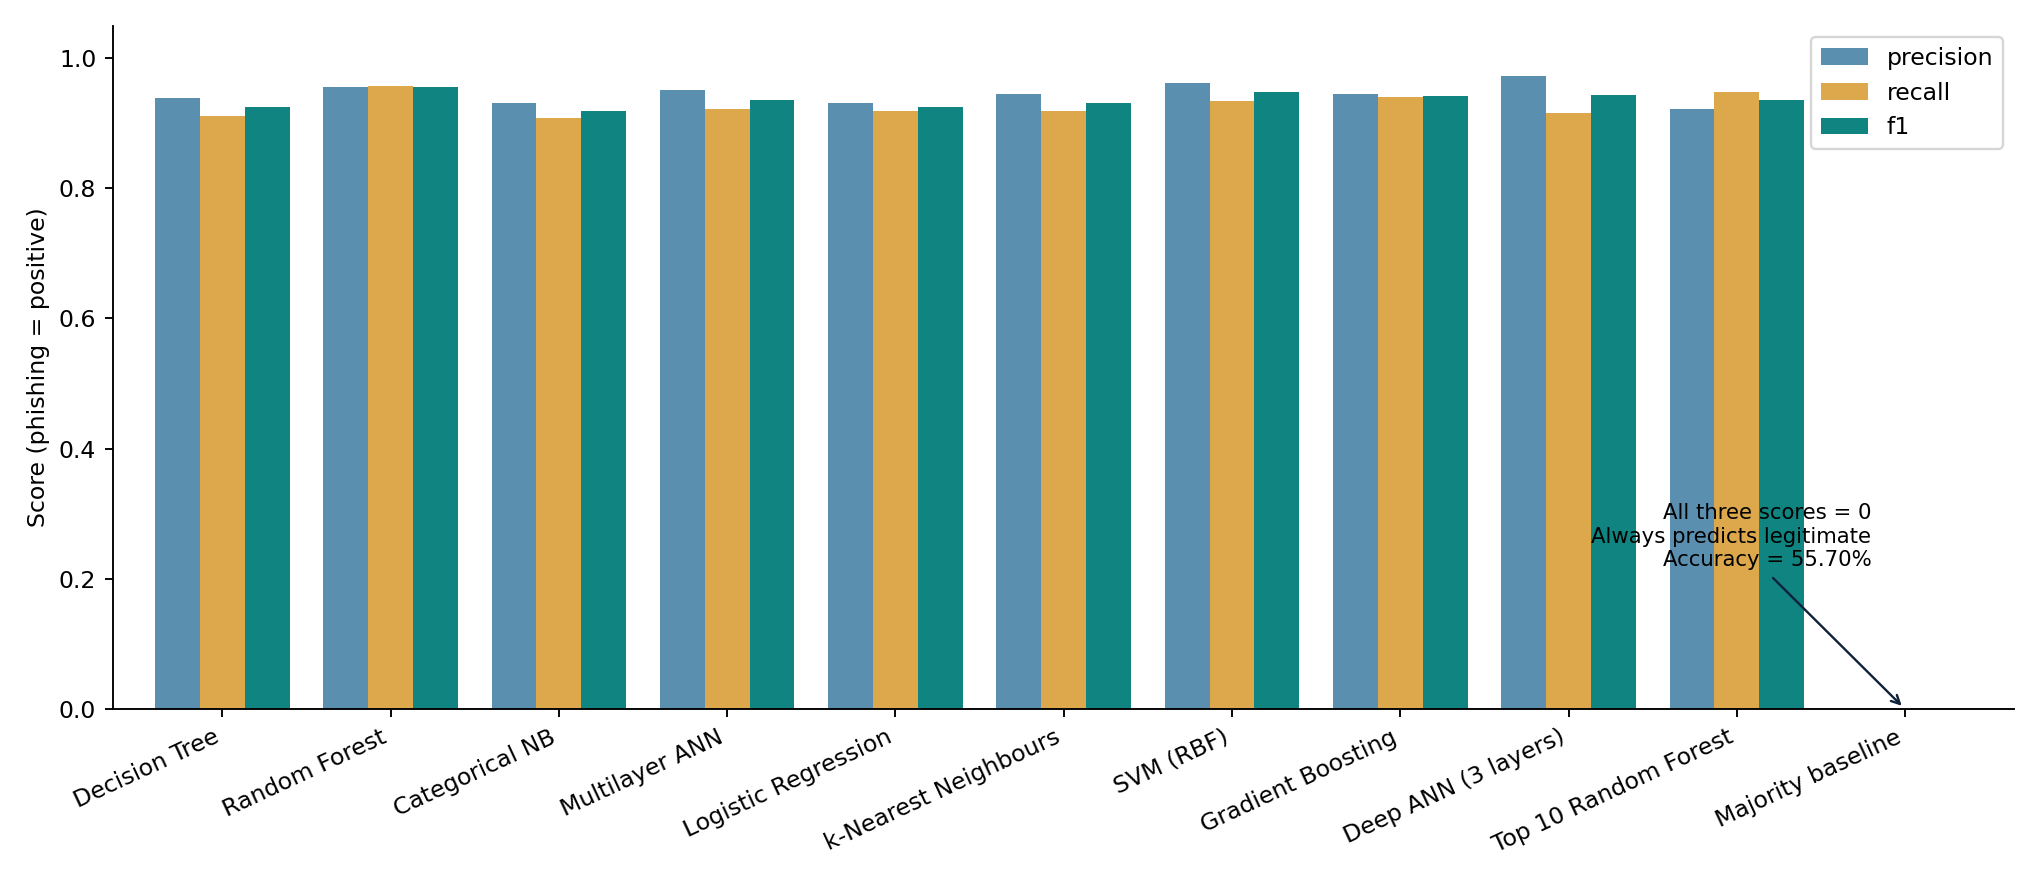

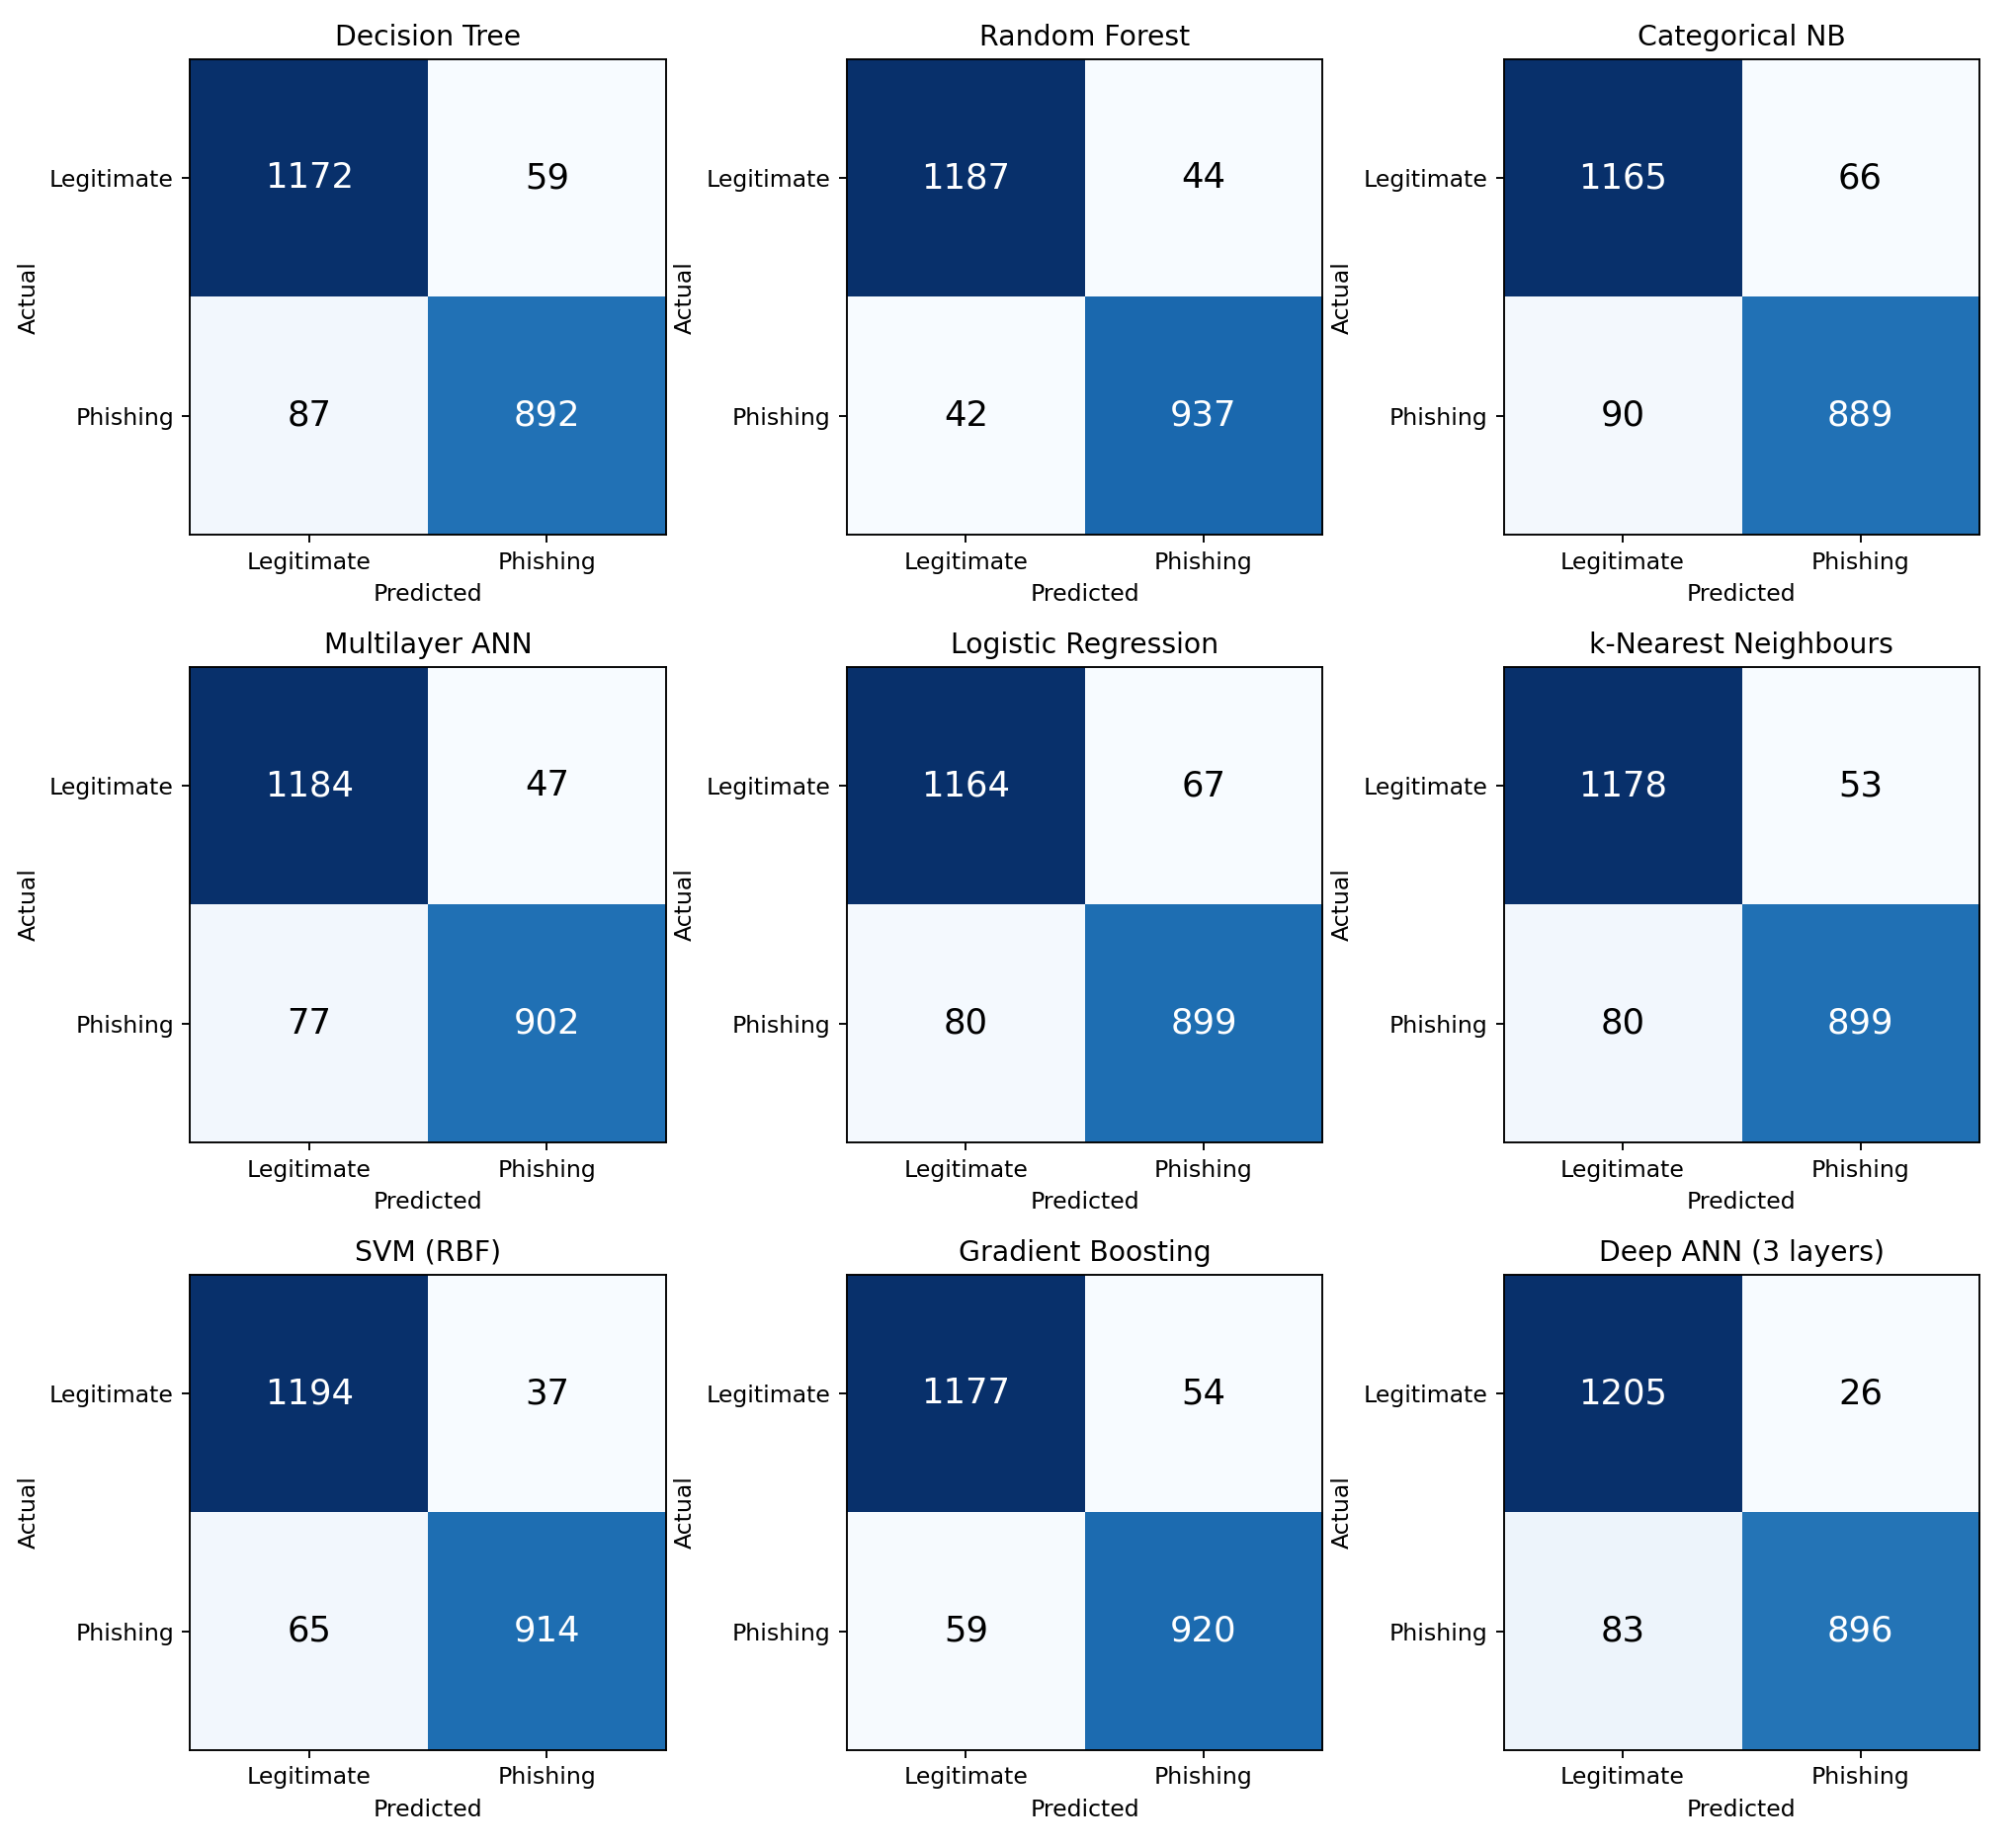

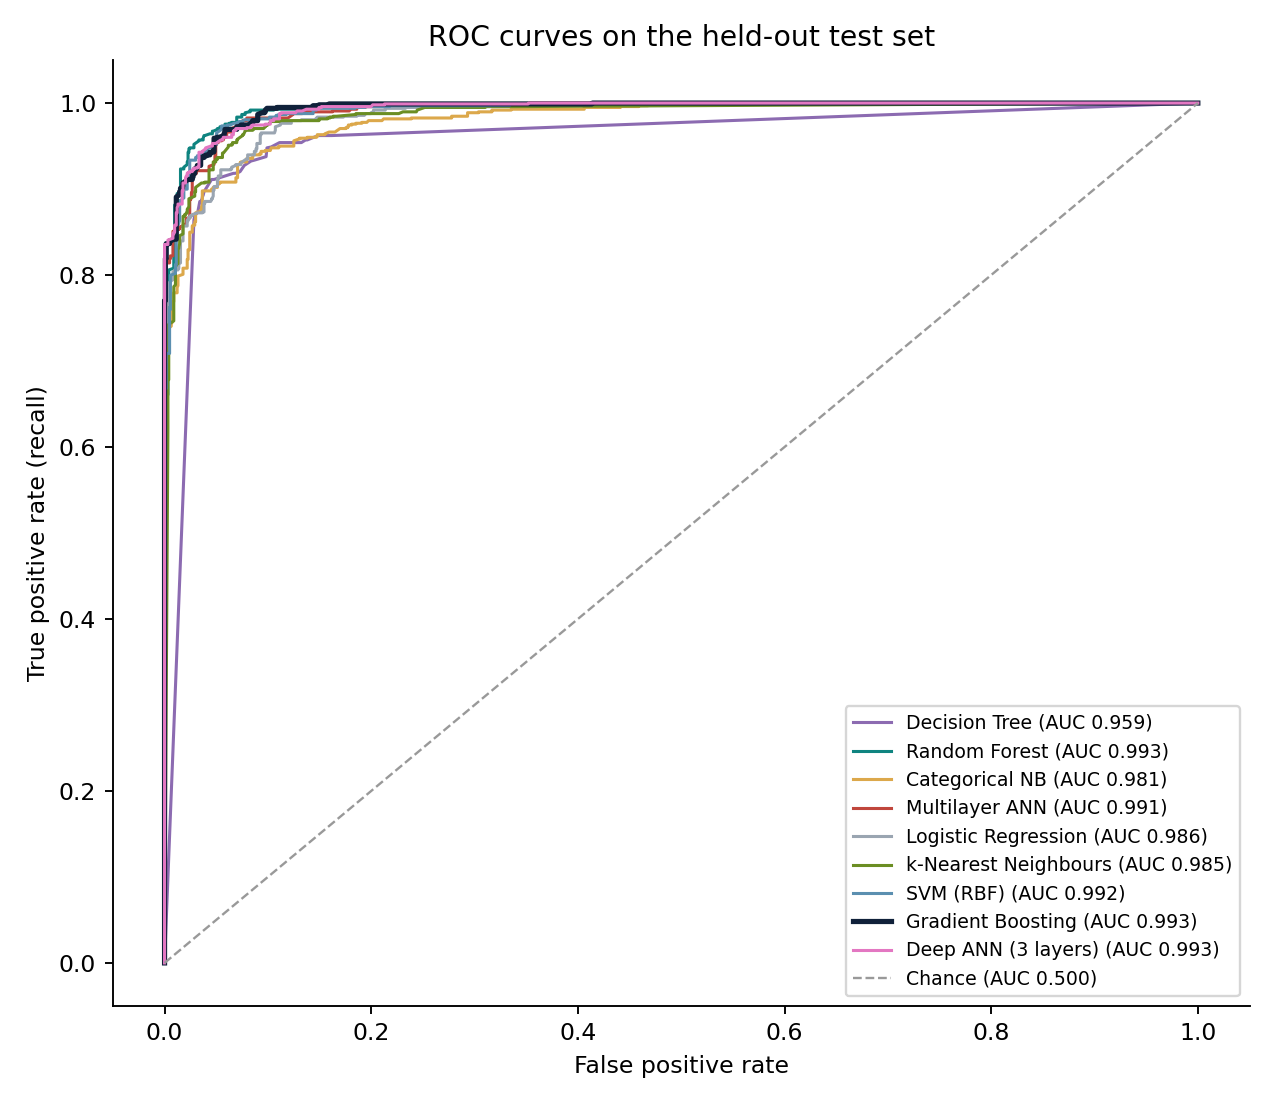

In [6]:
metrics=pd.read_csv(ROOT/'results/metrics.csv')
display(metrics.round(4))
display(Image(filename=str(ROOT/'results/model_comparison.png')))
display(Image(filename=str(ROOT/'results/confusion_matrices.png')))
display(Image(filename=str(ROOT/'results/roc_curves.png')))

Forest precision = 937/(937+38); recall = 937/(937+42). The majority baseline correctly labels legitimate records, but detects no phishing records and therefore has zero phishing F1.

## 6. Paired comparisons and limitations
Classical McNemar results apply Holm adjustment across nine comparisons. The two recurrent comparisons are saved separately without that correction. Repeated patterns challenge independent-row assumptions; these diagnostics do not establish definitive group-valid significance across all eleven rivals.

In [7]:
display(pd.read_csv(ROOT/'results/significance_mcnemar.csv'))

,reference,model,reference_right_other_wrong,reference_wrong_other_right,mcnemar_exact_p,holm_adjusted_p,significant_at_0.05
0,Gradient Boosting,Categorical NB,67,24,0.000007,0.000066,True
1,Gradient Boosting,Random Forest,8,35,0.000042,0.000335,True
2,Gradient Boosting,Decision Tree,55,22,0.000217,0.001518,True
3,Gradient Boosting,Logistic Regression,58,24,0.000222,0.001518,True
4,Gradient Boosting,k-Nearest Neighbours,53,33,0.039854,0.199268,False
5,Gradient Boosting,Top 10 Random Forest,58,42,0.133211,0.532842,False
6,Gradient Boosting,SVM (RBF),17,28,0.135156,0.532842,False
7,Gradient Boosting,Multilayer ANN,41,30,0.235098,0.532842,False
8,Gradient Boosting,Deep ANN (3 layers),37,41,0.734342,0.734342,False


## 7. Deep learning: deeper ANN, LSTM and RNN
Loss curves show development-set optimization progress, without proving convergence to an optimal solution. Recurrent networks impose a sequence on the fixed 30-column order, which has no natural temporal meaning. Their scores are below the forest in this recorded experiment.

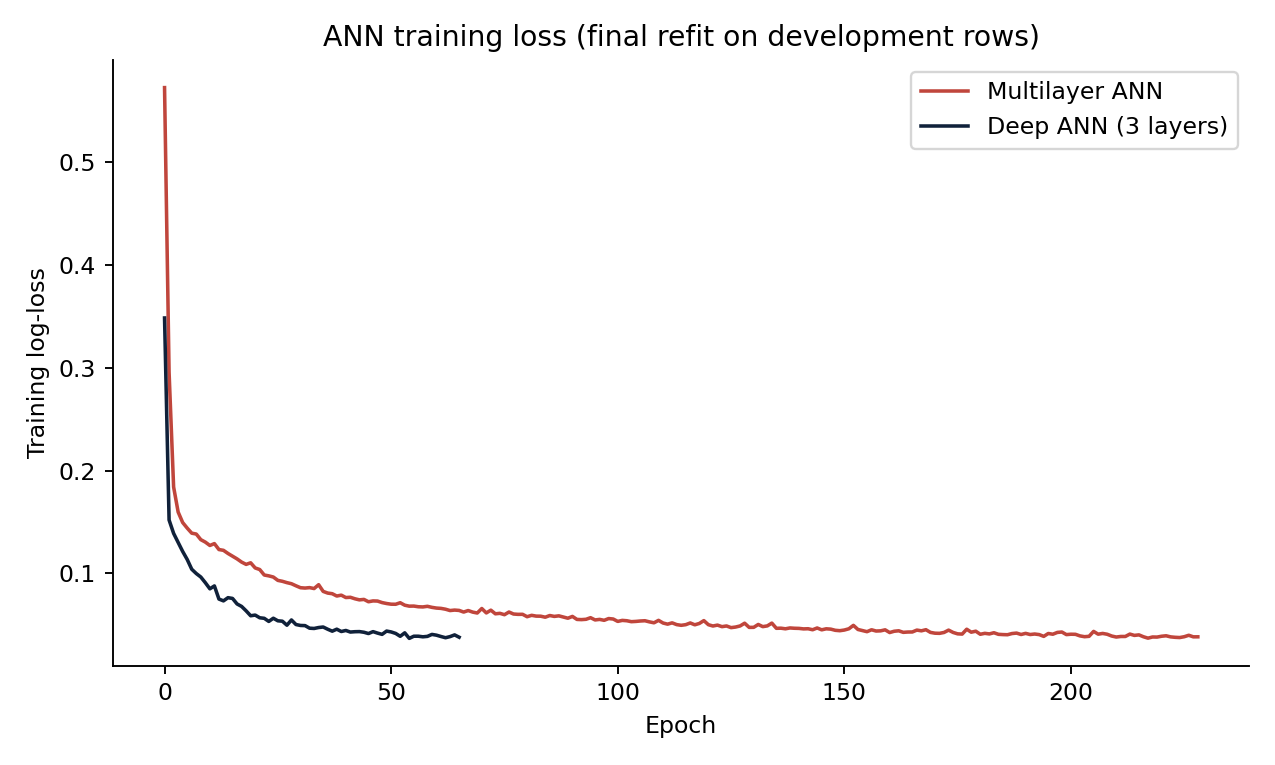

,model,cv_f1,cv_sd,epochs_per_fold,final_epochs,seconds,parameters
0,LSTM (bidirectional),0.941690,0.009058,"[43, 14, 24]",24,182.851682,"embed 16, hidden 32 x2 directions, dropout 0.2..."
1,Simple RNN (bidirectional),0.936295,0.007970,"[20, 11, 14]",14,38.230014,"embed 16, hidden 32 x2 directions, dropout 0.2..."


,model,accuracy,precision,recall,f1,f1_ci_low,f1_ci_high,roc_auc,TN,FP,FN,TP
0,LSTM (bidirectional),0.9357,0.9495,0.9030,0.9257,0.9035,0.9438,0.9877,1184,47,95,884
1,Simple RNN (bidirectional),0.9367,0.9320,0.9244,0.9282,0.9058,0.9486,0.9880,1165,66,74,905


,reference,model,reference_right_other_wrong,reference_wrong_other_right,mcnemar_exact_p
0,Gradient Boosting,LSTM (bidirectional),55,26,0.001689
1,Gradient Boosting,Simple RNN (bidirectional),49,22,0.001820


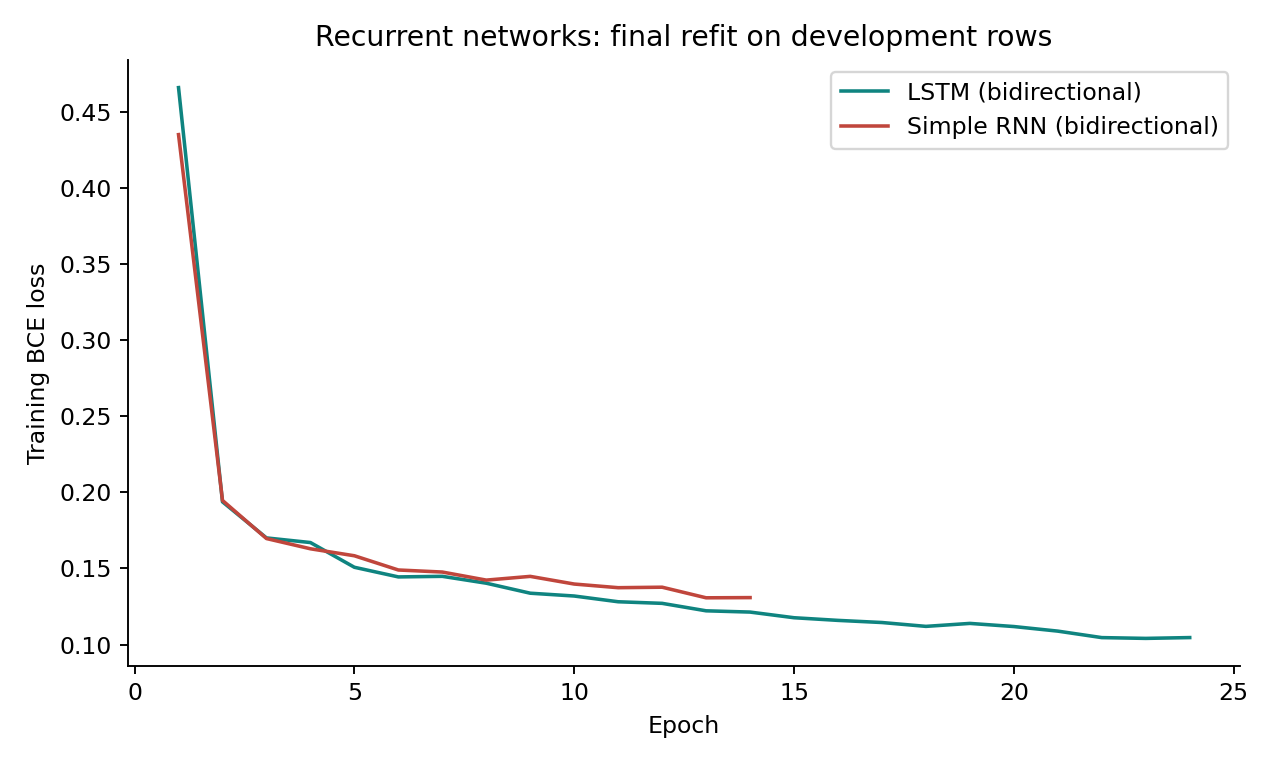

In [8]:
display(Image(filename=str(ROOT/'results/ann_loss_curves.png')))
dl=ROOT/'results/deep_learning_metrics.csv'
if dl.exists():
    display(pd.read_csv(ROOT/'results/deep_learning_cv.csv'))
    display(pd.read_csv(dl).round(4))
    display(pd.read_csv(ROOT/'results/deep_learning_mcnemar.csv'))
    display(Image(filename=str(ROOT/'results/dl_loss_curves.png')))
else:
    print('Run deep_learning_extension.py to create the LSTM/RNN results.')

## 8. Explainability and feature selection
Permutation importance: how much test F1 drops when one indicator is shuffled (explanation only, not used for selection). The top-10 mutual-information subset is an exploratory extension.

,feature,importance_mean,importance_sd
0,URL_of_Anchor,0.1521,0.0046
1,SSLfinal_State,0.1179,0.0047
2,Prefix_Suffix,0.0208,0.0028
3,web_traffic,0.0138,0.0041
4,having_Sub_Domain,0.0106,0.0020
5,Links_in_tags,0.0100,0.0033
6,having_IP_Address,0.0073,0.0027
7,Links_pointing_to_page,0.0070,0.0022
8,SFH,0.0062,0.0023
9,Google_Index,0.0044,0.0019


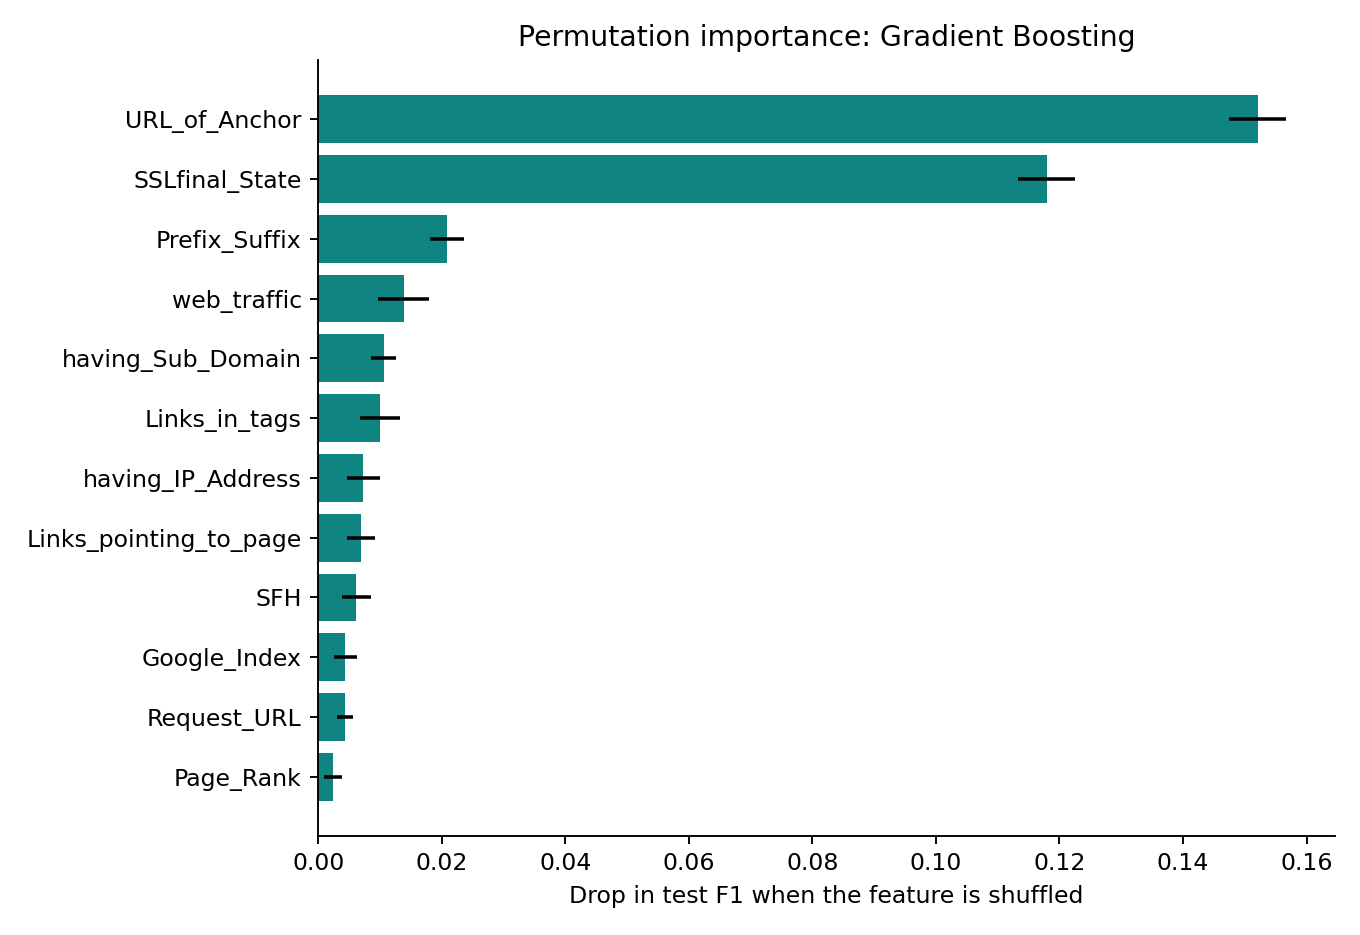

{'primary_model_selected_by_cv': 'Gradient Boosting',
 'best_required_model_by_cv': 'Random Forest',
 'subset_base_model': 'Random Forest',
 'subset_features': ['Prefix_Suffix',
  'having_Sub_Domain',
  'SSLfinal_State',
  'Domain_registeration_length',
  'Request_URL',
  'URL_of_Anchor',
  'Links_in_tags',
  'SFH',
  'age_of_domain',
  'web_traffic'],
 'subset_cv_f1': 0.9239408338478053,
 'note': 'Selection uses development CV F1 only. No changes to models or selection after test evaluation.'}

In [9]:
display(pd.read_csv(ROOT/'results/permutation_importance.csv').head(10).round(4))
display(Image(filename=str(ROOT/'results/permutation_importance.png')))
display(json.loads((ROOT/'results/selection.json').read_text()))

## 9. Saved prediction examples
These are predictions for held-out rows, not live URL scans.

In [10]:
examples=json.loads((ROOT/"results/demo_examples.json").read_text())
for case in examples:
    print(case["case"], "row", case["row_id"], "actual", case["actual"], "predicted", case["prediction"])
    display(pd.Series(case["features"]).to_frame("encoded value"))

correct_phishing row 2 actual 1 predicted 1


,encoded value
having_IP_Address,1
URL_Length,0
Shortining_Service,1
having_At_Symbol,1
double_slash_redirecting,1
Prefix_Suffix,-1
having_Sub_Domain,-1
SSLfinal_State,-1
Domain_registeration_length,-1
Favicon,1


missed_phishing row 96 actual 1 predicted 0


,encoded value
having_IP_Address,1
URL_Length,-1
Shortining_Service,1
having_At_Symbol,1
double_slash_redirecting,1
Prefix_Suffix,-1
having_Sub_Domain,1
SSLfinal_State,1
Domain_registeration_length,-1
Favicon,1


false_alarm row 120 actual 0 predicted 1


,encoded value
having_IP_Address,1
URL_Length,-1
Shortining_Service,1
having_At_Symbol,1
double_slash_redirecting,1
Prefix_Suffix,-1
having_Sub_Domain,-1
SSLfinal_State,-1
Domain_registeration_length,1
Favicon,1


## Assessment 4 report figures
These charts describe saved evidence without retraining or selecting new thresholds. The report interprets the class balance, feature patterns, F1 intervals, confusion matrix and ranking curves. The zero baseline is explicitly labelled.

01_data_audit.png


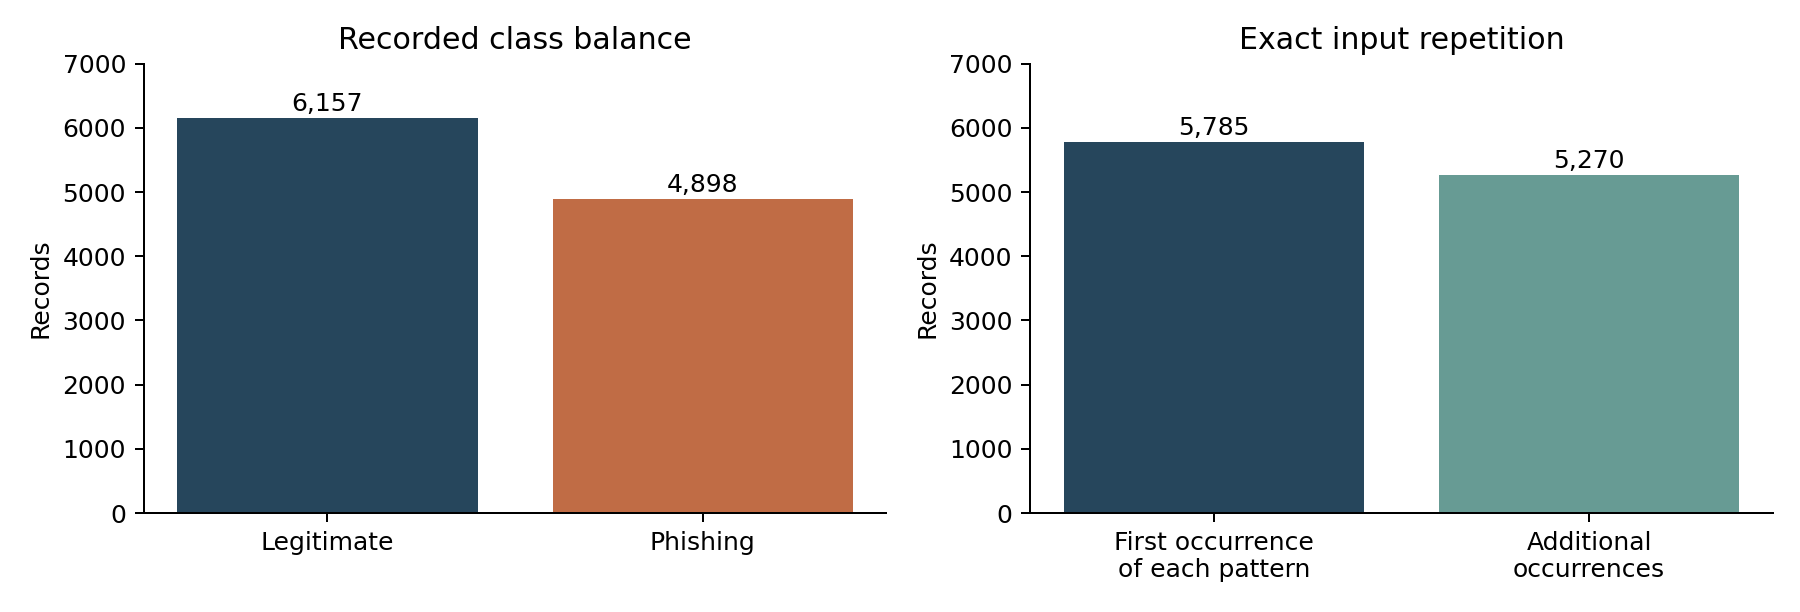

02_category_rates.png


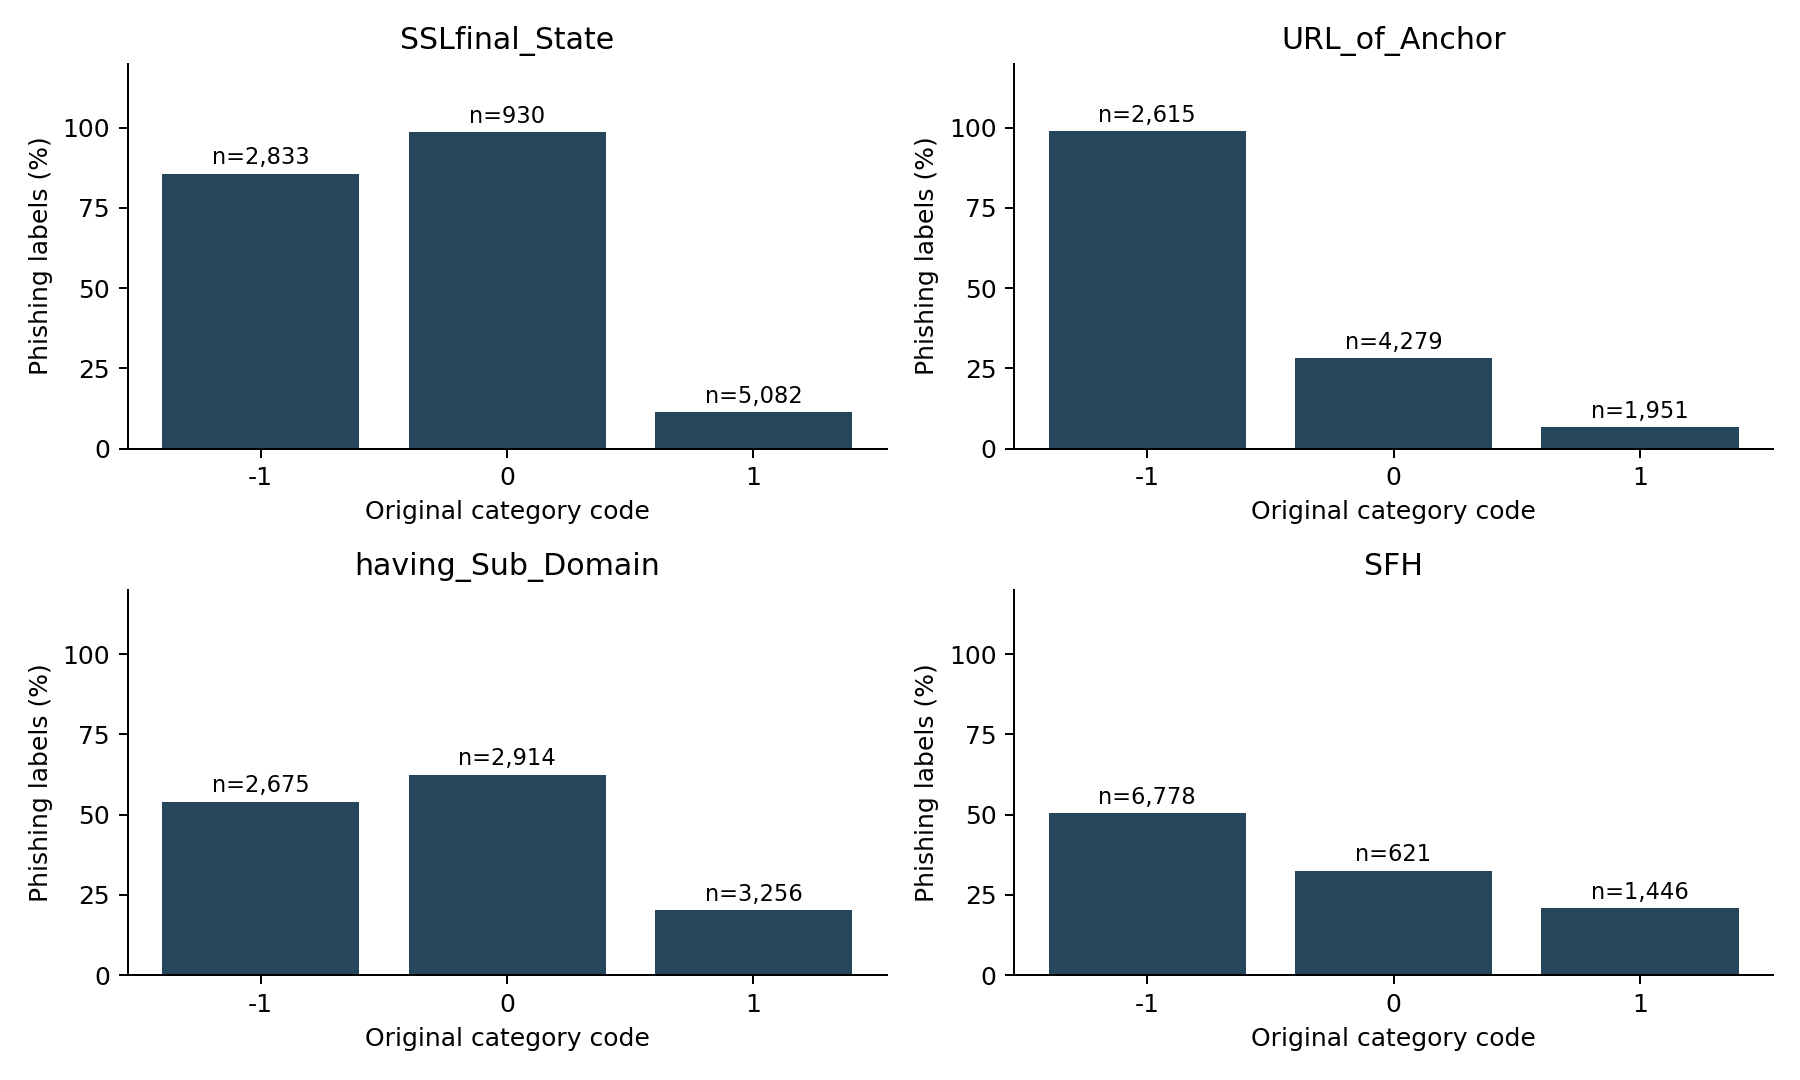

03_joint_rates.png


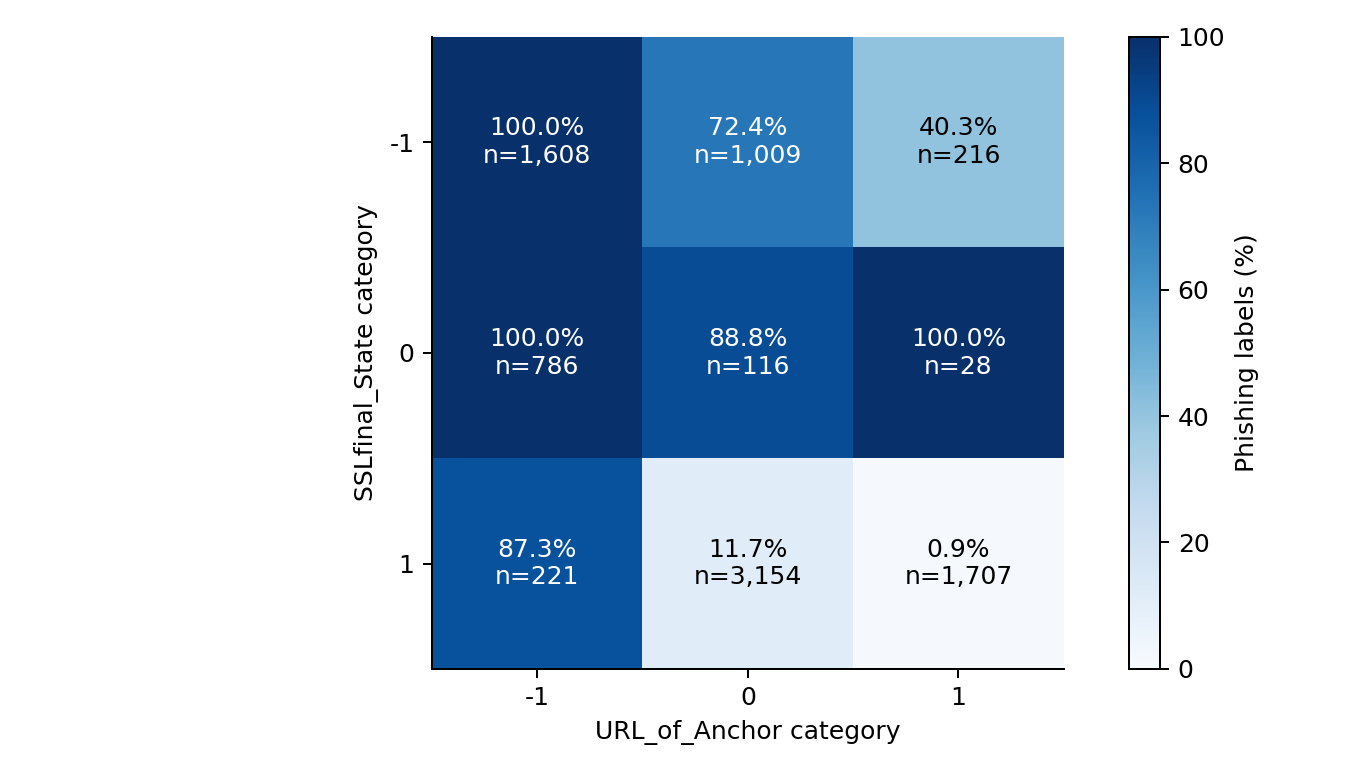

04_model_f1.png


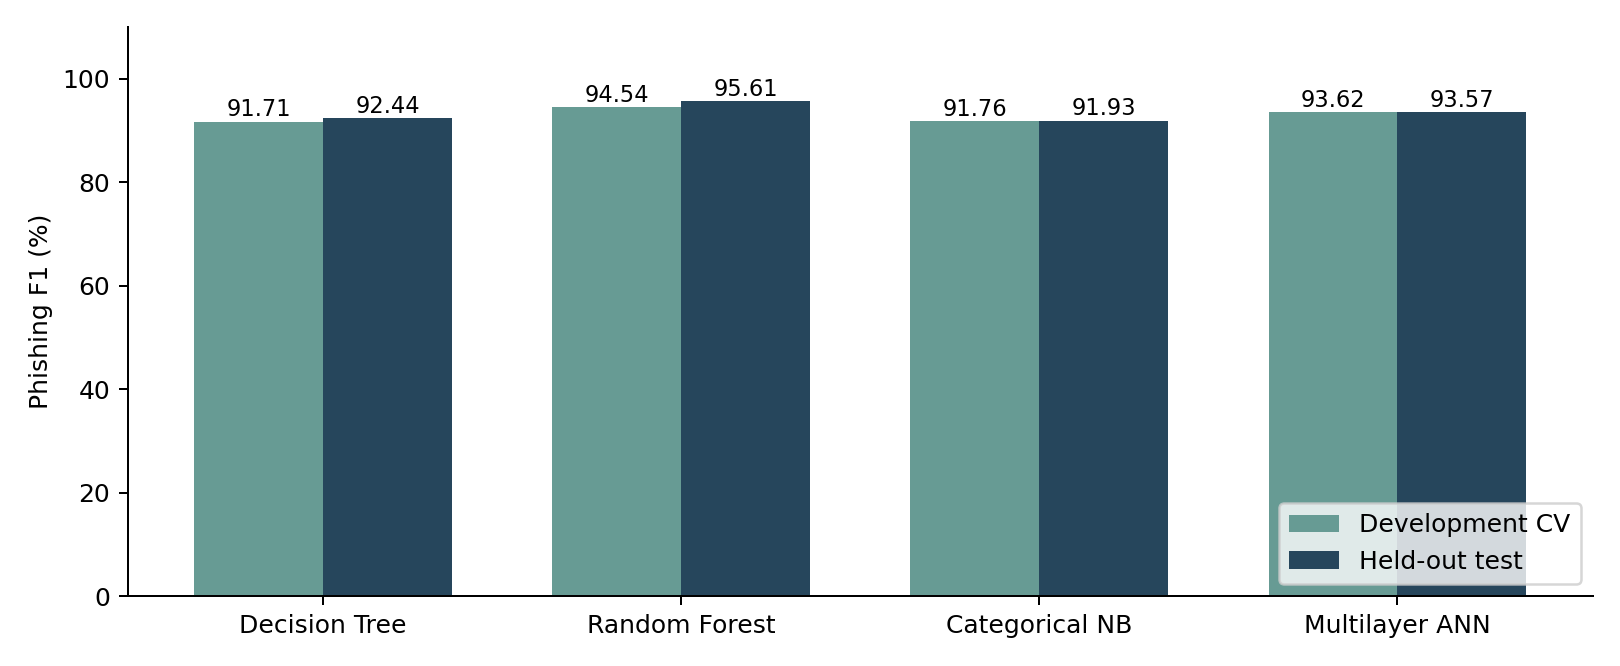

05_all_model_f1.png


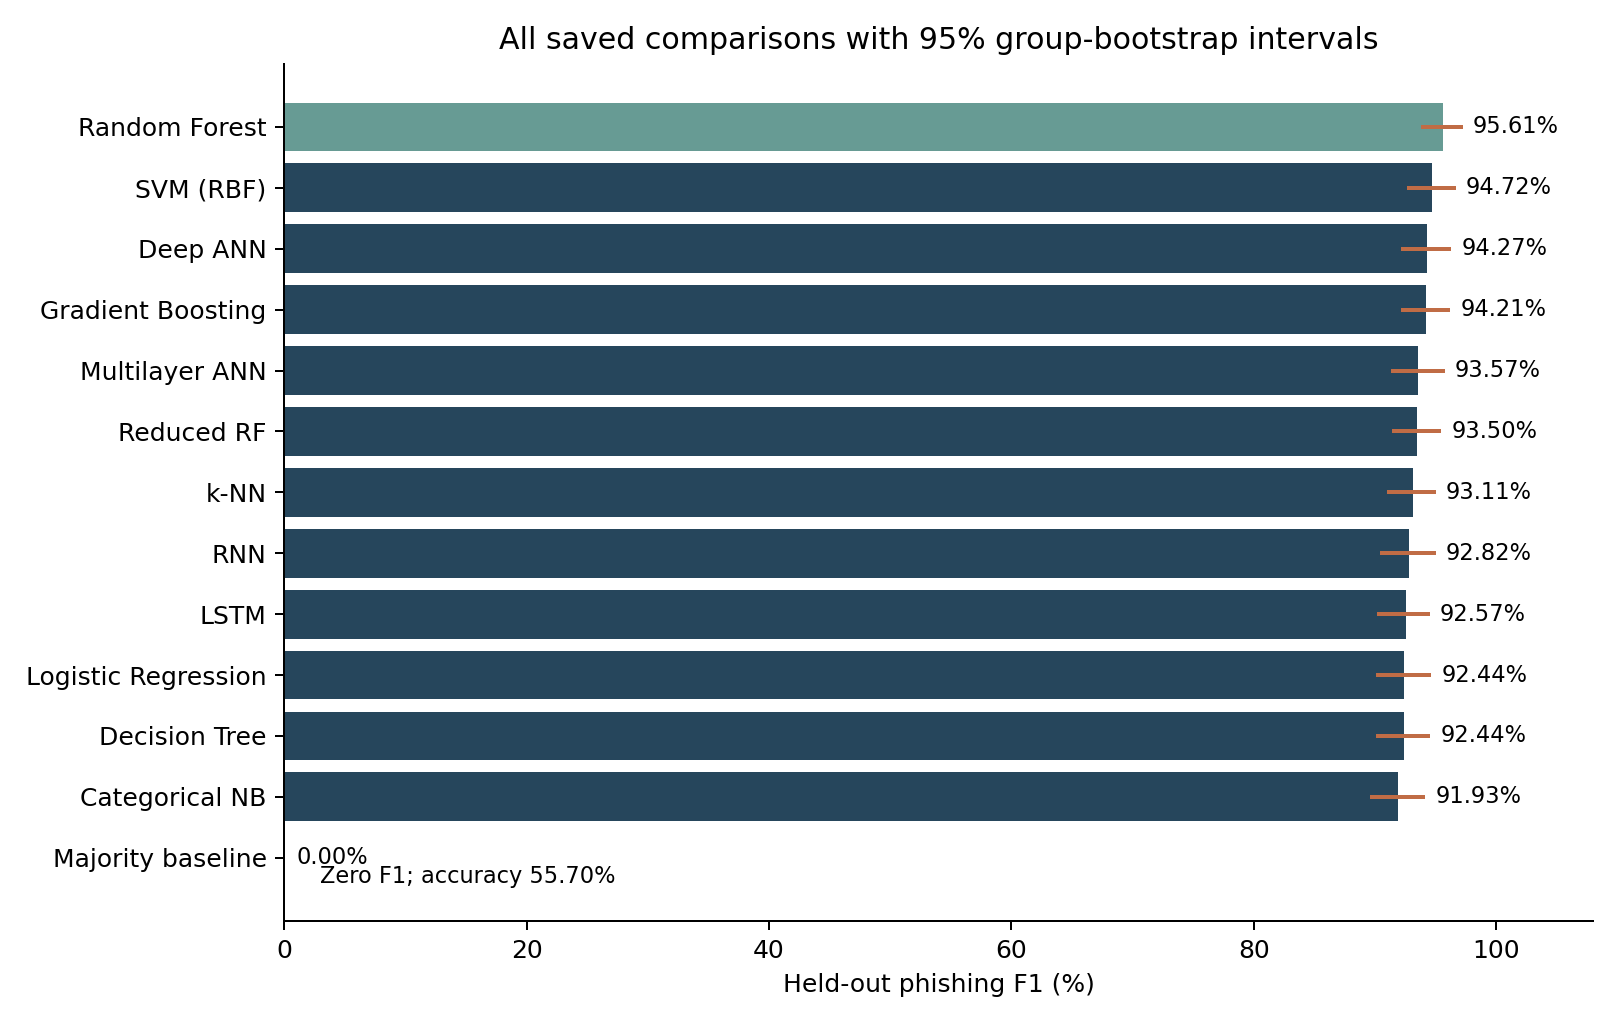

06_forest_confusion.png


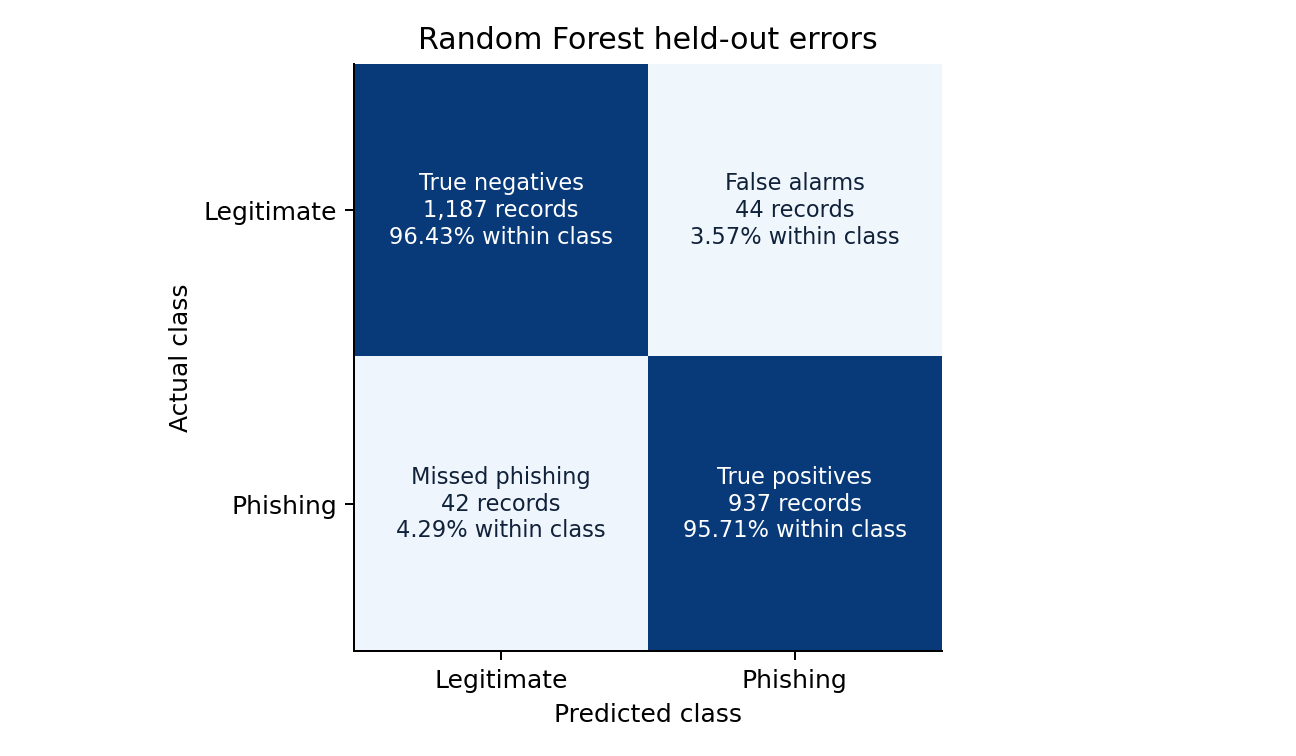

07_roc_precision_recall.png


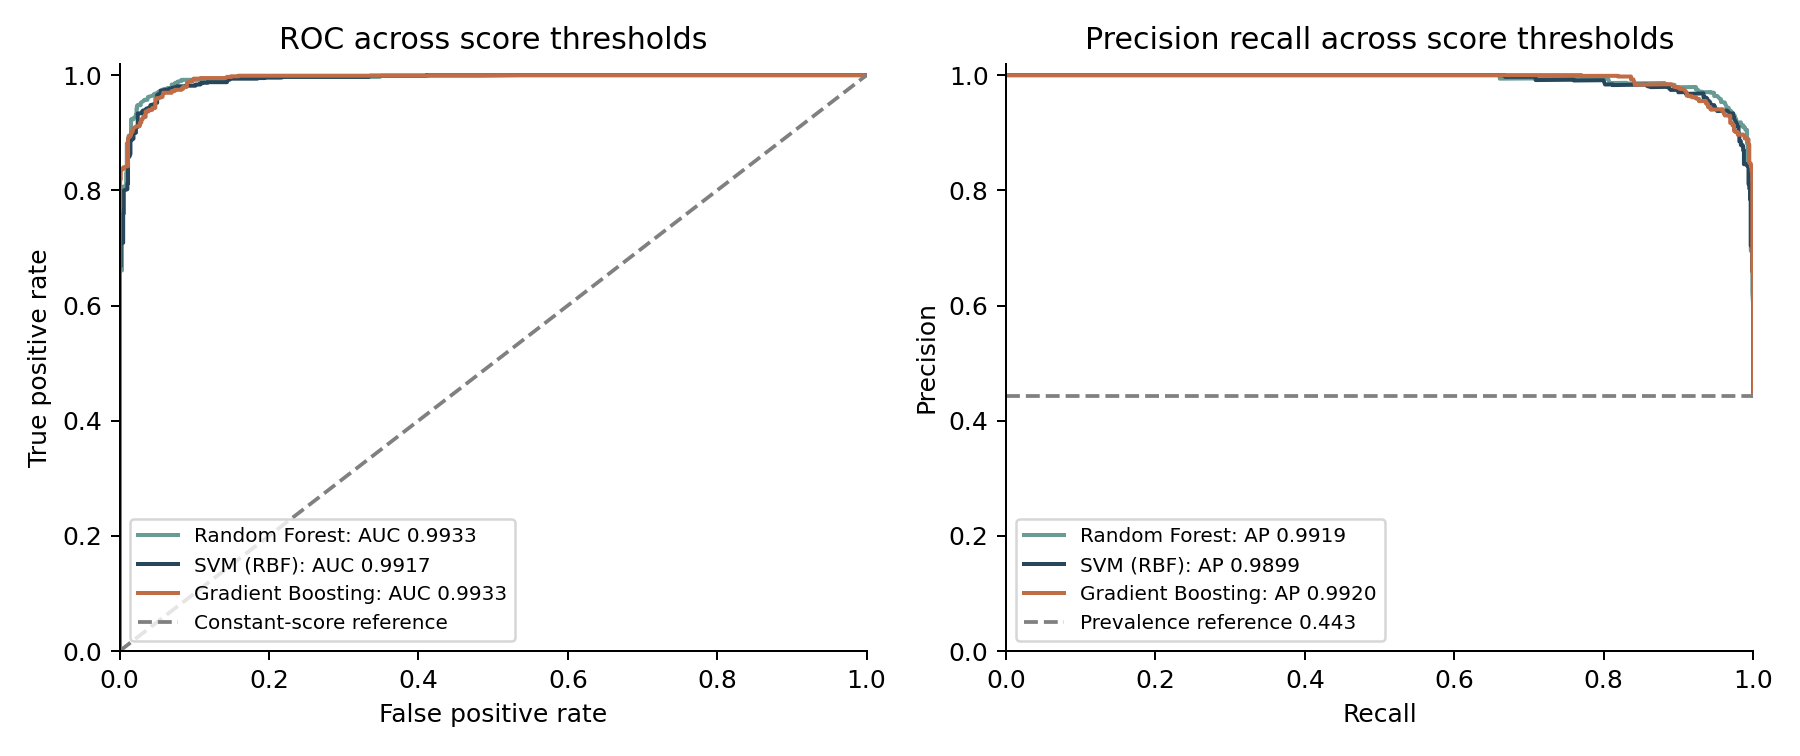

In [11]:
for chart in sorted((ROOT / "results/assessment4").glob("*.png")):
    print(chart.name)
    display(Image(filename=str(chart), width=850))


## 10. Conclusion and interpretation
Random Forest was selected among nine scikit-learn candidates using development CV F1 (94.58%; Gradient Boosting 94.57%). It achieves 96.38% accuracy and 95.91% phishing F1 on 2,210 held-out records, with 42 missed phishing records and 38 false alarms. Group-bootstrap F1 interval: approximately 94.3–97.3%, conditional on these data and the fitted model.

Grouping avoids identical input patterns appearing in training and test partitions. The 42 false negatives are labelled phishing records classified as legitimate, a potentially serious failure in a screening setting. They do not estimate the number of attacks missed in actual deployment.

The deeper ANN reaches 94.27% F1; LSTM 93.03%; RNN 92.82%. Their inclusion does not change the primary CV selection. Statistical comparisons remain exploratory because of group dependence and differing correction scopes.

Historical data, pre-extracted features, one outer partition and absent domain/time identifiers limit present-day claims. This benchmark supports further evaluation, not deployment readiness. See ../Assessment4_Report.pdf for the complete discussion and references.